<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ HOLOGY 9.0 HoloMine Task 2: Prediksi Harga Properti dari Teks Penjualan ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Regresi harga listing dari deskripsi tidak terstruktur menggunakan DeBERTa-v3-large</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **HoloMine Price Regression**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Rekayasa Fitur**](#4)
5. [**Desain Validasi**](#5)
6. [**Model Dasar**](#6)
7. [**Pemodelan Transformer**](#7)
8. [**Penggabungan dan Kalibrasi**](#8)
9. [**Submisi**](#9)
10. [**Pasca-Analisis**](#10)
11. [**Daftar Pustaka**](#11)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Platform properti digital menghasilkan jutaan listing yang memuat deskripsi penjualan dalam bahasa bebas. Informasi yang menentukan harga, seperti luas bangunan, jumlah kamar, kondisi renovasi, dan lokasi, tertanam di dalam kalimat dan bukan pada kolom terstruktur. Pada **HOLOGY 9.0 HoloMine Task 2**, peserta diminta memprediksi `listPrice` hanya dari teks tersebut.

- **Tugas**: regresi harga properti dari satu kolom teks
- **Metrik**: Mean Absolute Error dalam dolar
- **Platform**: Vast.ai, satu NVIDIA RTX 5090 (32 GB, Blackwell sm_120)

---

## Dataset

*Dataset* berisi 14.640 baris latih dan 3.659 baris uji, masing-masing dengan `id` dan `text`. Kolom `listPrice` hanya tersedia pada data latih. Seluruh atribut terstruktur sudah dihapus panitia, sehingga satu-satunya sumber informasi adalah prosa penjualan.

| Berkas | Baris | Kolom |
| --- | --- | --- |
| `train.csv` | 14.640 | `id`, `text`, `listPrice` |
| `test.csv` | 3.659 | `id`, `text` |
| `sample_submission.csv` | 3.659 | `id`, `listPrice` |

Harga membentang dari 1 dolar sampai 80 juta dolar dengan median 499.900. Rentang enam orde besaran inilah yang membuat pemilihan ruang target menjadi keputusan terpenting pada kasus ini.

---

## Metrik

Submisi dinilai dengan *Mean Absolute Error* pada skala dolar.

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|$$

MAE diminimalkan oleh **median bersyarat**, bukan rata-rata bersyarat. Karena fungsi `exp` bersifat monoton, median harga sama dengan eksponensial dari median log harga:

$$\text{median}(y \mid x) = \exp\big(\text{median}(\log y \mid x)\big)$$

Konsekuensinya sangat konkret dan dipakai di seluruh notebook: model diregresikan pada log harga dengan objektif bertipe L1, lalu hasilnya dieksponensialkan. Regresi langsung pada dolar mentah akan mengejar rata-rata bersyarat dan meleset dari metrik.

---

## Pendekatan: DeBERTa-v3-large pada Log Harga + *Late Fusion*

DeBERTa-v3 menggunakan *disentangled attention*, yaitu pemisahan representasi konten dan posisi pada perhitungan atensi, serta dilatih dengan objektif *replaced token detection* bergaya ELECTRA (He dkk., 2023). Pada korpus berbahasa Inggris berukuran menengah, arsitektur ini lebih unggul secara efisiensi sampel dibanding encoder multibahasa maupun ModernBERT.

```
DeBERTa-v3-large (fine-tune penuh, 640 token)
    |
    +-- last_hidden_state [1024-dim per token]
    +-- mean pooling berbobot attention_mask
         |
    Linear(1024, 1) -> z (log harga terstandardisasi)
         |
    inverse scaler -> exp() -> harga dolar
```

Prediksi transformer digabung secara *late fusion* dengan tiga model klasik, yaitu ridge dan LinearSVR di atas TF-IDF kata dan karakter, serta LightGBM di atas fitur hasil ekstraksi regex ditambah 192 komponen SVD. Bobot dicari pada prediksi *out-of-fold*, lalu kalibrasi dipilih secara *cross-fit* agar skor yang dilaporkan tidak optimistis.

---

## Riwayat Iterasi

Setiap angka di bawah berasal dari fold yang sama, sehingga perbandingannya sah.

| Iterasi | Perubahan utama | MAE OOF | MAE *Public Leaderboard* |
| --- | --- | --- | --- |
| v1 | ModernBERT-large, target `price / 1e6`, Huber | 470.941 | 419293.45779 |
| v2 sparse | target log, TF-IDF + LightGBM | 326.358 | 408870.51993 |
| v2 penuh | DeBERTa-v3-large 3 epoch | 277.185 | 3329329.08001 |
| **v3** | **optimizer diperbaiki, 5 epoch** | **267.139** | **310223.76589** |

Pelajaran terbesar ada pada baris pertama. v1 melatih ModernBERT-large langsung pada dolar dan kalah dari ridge TF-IDF sederhana. Penyebabnya bukan arsitektur melainkan ruang target, dan perbaikan satu baris kode menghasilkan penurunan 30,8 persen.

---

## Referensi Utama

- `src/eda/01` sampai `src/eda/13` -- tiga belas analisis mandiri, masing-masing mencetak angka dan menyimpan figur
- `reports/findings.md` -- rangkuman temuan beserta keputusan pemodelan yang dipaksakannya
- `reports/figures/` -- figur untuk setiap analisis
- `src/prep/01` sampai `src/prep/04` -- pembangunan dataset, verifikasinya, dan submisi CPU

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

RTX 5090 memakai arsitektur Blackwell dengan *compute capability* 12.0, sehingga *wheel* PyTorch harus dibangun untuk CUDA 12.8 atau lebih baru. Sel berikut memeriksa apakah torch bawaan *image* sudah mendukung `sm_120` dan hanya mengunduh ulang apabila belum, lalu memasang sisa dependensi.

In [1]:
%pip install -q --upgrade pip
!python -c "import sys, torch; sys.exit(0 if 'sm_120' in torch.cuda.get_arch_list() else 1)" || pip install -q torch --index-url https://download.pytorch.org/whl/cu128
%pip install -q 'transformers>=4.46' tokenizers sentencepiece tiktoken protobuf accelerate
%pip install -q scikit-learn lightgbm pandas pyarrow matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.
/bin/bash: line 1: python: command not found
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikumpulkan dalam satu sel agar dependensi setiap bagian notebook terlihat sekaligus dan mudah ditelusuri.

In [2]:
import gc
import json
import math
import os
import random
import re
import time
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.sparse import csr_matrix, hstack
from scipy.optimize import nnls
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import LinearSVR
from scipy.sparse.csgraph import connected_components
from scipy.sparse import coo_matrix
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)

---

Sel berikut mencetak kapabilitas GPU sebelum pelatihan dimulai. Menemukan ketidakcocokan versi di sini jauh lebih murah daripada menemukannya setelah satu fold berjalan setengah jam.

In [3]:
print('torch     :', torch.__version__)
print('cuda      :', torch.version.cuda)
print('device    :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    major, minor = torch.cuda.get_device_capability(0)
    total = torch.cuda.get_device_properties(0).total_memory / 1024 ** 3
    print(f'capability: sm_{major}{minor}')
    print(f'vram      : {total:.1f} GiB')
    print('bf16 ok   :', torch.cuda.is_bf16_supported())
    assert major >= 8, 'notebook ini mengasumsikan bf16, butuh Ampere atau lebih baru'

torch     : 2.11.0+cu128
cuda      : 12.8
device    : NVIDIA GeForce RTX 5090
capability: sm_120
vram      : 31.4 GiB
bf16 ok   : True


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan sebelum setiap fold, sehingga urutan *sampling*, inisialisasi *head*, dan *dropout* dapat diulang. `cudnn.benchmark` dibiarkan aktif karena keuntungan kecepatannya lebih besar daripada determinisme penuh pada kasus ini.

In [4]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything(42)

---

## Konfigurasi

Kelas `Config` memusatkan seluruh *hyperparameter*. `PROFILE` mengatur pertukaran antara waktu dan skor: `smoke` untuk memastikan seluruh sel berjalan dalam beberapa menit, `full` untuk run final.

Tiga nilai layak disorot. `max_length` 640 dipilih dari EDA, karena persentil 99 panjang teks uji setara sekitar 790 token dan jendela 512 justru memotong listing mewah yang menyumbang mayoritas MAE. `fold_time_budget_minutes` adalah pagar waktu **per fold**, bukan total, sehingga lima fold dijamin selesai meski waktu sewa GPU terbatas. `early_stopping_evals` disetel longgar setelah percobaan menunjukkan bahwa penghentian dini yang agresif memotong justru pada fase *annealing* ketika perbaikan terbesar terjadi.

In [36]:
PROFILE = 'full'


@dataclass
class Config:
    data_dir: Path = Path('data')
    out_dir: Path = Path('outputs/v2')
    seed: int = 42
    n_folds: int = 5
    price_floor: float = 10_000.0
    duplicate_threshold: float = 0.85
    twin_threshold: float = 0.97
    backbones: tuple = (
        ('microsoft/deberta-v3-large', 640, 8, 2, 1.0e-5),
    )
    epochs: float = 5.0
    fold_time_budget_minutes: float = 24.0
    early_stopping_evals: int = 99
    head_lr: float = 1.0e-4
    llrd: float = 0.9
    weight_decay: float = 0.01
    warmup_ratio: float = 0.06
    huber_beta: float = 0.25
    evals_per_epoch: int = 2
    max_grad_norm: float = 1.0
    gradient_checkpointing: bool = False
    infer_batch_size: int = 32


CFG = Config()
if PROFILE == 'smoke':
    CFG.n_folds = 2
    CFG.epochs = 0.25
    CFG.fold_time_budget_minutes = 10.0
    CFG.backbones = (('microsoft/deberta-v3-base', 384, 16, 1, 2.0e-5),)

for candidate in (Path('data'), Path('../data'), Path('/workspace/data')):
    if (candidate / 'train.csv').exists():
        CFG.data_dir = candidate
        CFG.out_dir = candidate.parent / 'outputs' / 'v2'
        break
else:
    raise FileNotFoundError('data/train.csv tidak ditemukan, salin folder data ke sebelah notebook')

CFG.out_dir.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(json.dumps({k: str(v) for k, v in asdict(CFG).items()}, indent=2))

{
  "data_dir": "data",
  "out_dir": "outputs/v2",
  "seed": "42",
  "n_folds": "5",
  "price_floor": "10000.0",
  "duplicate_threshold": "0.85",
  "twin_threshold": "0.97",
  "backbones": "(('microsoft/deberta-v3-large', 640, 8, 2, 1e-05),)",
  "epochs": "5.0",
  "fold_time_budget_minutes": "24.0",
  "early_stopping_evals": "99",
  "head_lr": "0.0001",
  "llrd": "0.9",
  "weight_decay": "0.01",
  "warmup_ratio": "0.06",
  "huber_beta": "0.25",
  "evals_per_epoch": "2",
  "max_grad_norm": "1.0",
  "gradient_checkpointing": "False",
  "infer_batch_size": "32"
}


---

## Muat Data

Berkas kompetisi dibaca apa adanya, lalu jumlah baris dan susunan kolomnya diperiksa terhadap deskripsi resmi sebelum diproses lebih lanjut. Urutan `id` pada submisi juga dipastikan sama dengan `sample_submission.csv`.

In [6]:
train = pd.read_csv(CFG.data_dir / 'train.csv')
test = pd.read_csv(CFG.data_dir / 'test.csv')
sample_submission = pd.read_csv(CFG.data_dir / 'sample_submission.csv')

train['text'] = train['text'].fillna('')
test['text'] = test['text'].fillna('')

print('train', train.shape)
print('test ', test.shape)
print('sub  ', sample_submission.shape)
assert list(train.columns) == ['id', 'text', 'listPrice']
assert list(test.columns) == ['id', 'text']
assert test['id'].tolist() == sample_submission['id'].tolist()
train.head(3)

train (14640, 3)
test  (3659, 2)
sub   (3659, 2)


,id,text,listPrice
0,RE_009688,"Nestled in the heart of Randolph, [Redacted En...",185000.0
1,RE_015920,Beautiful end-unit townhouse in desirable Quin...,175000.0
2,RE_014937,Lovely 1925 bungalow! Forced air. Unfinished b...,339500.0


---

Statistik ringkas target dicetak untuk menegaskan keputusan ruang log, sekaligus menetapkan garis dasar yang harus dilewati model apa pun.

In [7]:
y_price = train['listPrice'].to_numpy(dtype=float)
log_price = np.log(np.clip(y_price, CFG.price_floor, None))

print(f'median      {np.median(y_price):>14,.0f}')
print(f'mean        {y_price.mean():>14,.0f}')
print(f'max         {y_price.max():>14,.0f}')
print(f'skew raw    {pd.Series(y_price).skew():>14.2f}')
print(f'skew log    {pd.Series(log_price).skew():>14.2f}')
print(f'MAE median-constant baseline: {np.abs(y_price - np.median(y_price)).mean():,.0f}')

median             499,900
mean               839,073
max             80,000,000
skew raw             15.29
skew log             -0.22
MAE median-constant baseline: 550,252


> ### Insights
>
> Kemencengan turun dari 15,29 menjadi -0,22 hanya dengan logaritma. Distribusi log praktis simetris, yang berarti satu unit gradien di ruang log memberi bobot setara pada rumah 200 ribu dan rumah 20 juta. Di ruang dolar, 1,5 persen baris termahal akan menguasai hampir seluruh gradien dan model berhenti belajar dari mayoritas data.
>
> Baseline konstan median memberi MAE 550.252. Angka ini adalah garis yang harus dilewati model apa pun sebelum dianggap mempelajari sesuatu dari teks.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Seluruh analisis pada bagian ini dijalankan terpisah di `src/eda/` agar dapat diulang di laptop tanpa GPU, dan hasilnya diringkas di sini karena setiap temuan memaksa satu keputusan pemodelan yang konkret. Figur untuk masing-masing analisis tersimpan di `reports/figures/`.

---

## Geometri Target dan Apa yang Diminta Metrik

`src/eda/01_target_geometry.py` mengukur bentuk distribusi harga dan membandingkan tiga penduga konstan. Perbandingan ini bukan formalitas: ia menunjukkan secara empiris bahwa MAE meminta median, bukan rata-rata.

| Penduga konstan | Nilai | MAE |
| --- | --- | --- |
| rata-rata | 839.073 | 651.668 |
| **median** | **499.900** | **550.252** |
| rata-rata geometrik | 486.214 | 550.669 |

Selanjutnya, massa kesalahan dipetakan terhadap pita harga, relatif terhadap baseline median.

| Pita harga | Baris | Porsi baris | Porsi MAE |
| --- | --- | --- | --- |
| < 500 ribu | 7.386 | 50,4% | 19,2% |
| 500 ribu - 1,5 juta | 5.913 | 40,4% | 22,3% |
| 1,5 - 5 juta | 1.121 | 7,7% | 27,5% |
| > 5 juta | 220 | 1,5% | **31,0%** |

> ### Insights
>
> Tiga puluh satu persen dari seluruh MAE berasal dari 220 baris di atas lima juta dolar, dan 500 listing termahal (3,4 persen baris) menyumbang 42 persen. Akurasi di tengah pasar hampir gratis dan hampir tidak bernilai; yang menentukan skor adalah ujung atas distribusi.
>
> Implikasi langsung ke pemodelan: jendela konteks tidak boleh memotong listing panjang, karena listing mewah justru yang paling panjang. Inilah alasan `max_length` disetel 640 dan bukan 512.

---

## Pemilihan Ruang Target

`src/eda/07_target_transform_and_loss.py` menjalankan model dan fold yang sama pada empat ruang target berbeda. Eksperimen ini adalah yang paling menentukan pada keseluruhan proyek.

| Ruang target | MAE OOF |
| --- | --- |
| dolar mentah | 514.990 |
| `price / 1e6` | 514.990 |
| akar dolar | 363.684 |
| **log dolar** | **356.188** |

Perpindahan dari ruang dolar ke ruang log memberi perbaikan 30,8 persen dari satu baris kode, lebih besar daripada efek pergantian arsitektur mana pun yang tersedia.

> ### Insights
>
> Kemencengan target per ruang menjelaskan sebabnya: 15,29 pada dolar mentah, 4,23 pada akar, dan -0,22 pada log. Loss kuadratik maupun Huber di ruang dolar membelanjakan hampir seluruh gradiennya pada 1,5 persen baris termahal.
>
> Iterasi pertama proyek ini meregresikan `price / 1e6` dengan Huber dan mencatat MAE 632.642 menggunakan ModernBERT-large, lebih buruk daripada ridge TF-IDF. Arsitektur tidak pernah menjadi masalahnya.

---

## Kualitas Teks dan Kerusakan Sistematis

`src/eda/02_text_quality_audit.py` menginventarisasi kerusakan yang dibawa *scraper*, lalu mengukur tingkat kemunculannya pada kedua split.

| Cacat | Latih | Uji |
| --- | --- | --- |
| pemisah ribuan terbelah menjadi `", "` | 4,41% | 5,44% |
| titik kalimat kehilangan spasi | 11,41% | 7,38% |
| penanda `[Redacted Entity]` | 14,02% | 17,76% |

Cacat pertama paling berbahaya karena diam-diam mengubah angka. Teks `"this 2, 557-square-foot residence"` sebenarnya berarti 2557 kaki persegi, tetapi setiap pengurai angka membacanya sebagai 2 lalu 557. Aliran angka berubah pada **seluruh 646 baris latih** yang terdampak, dan nilai `sqft` hasil parsing berubah pada 345 baris, dari median 547 menjadi 2.585.

> ### Insights
>
> Penanda `[Redacted Entity]` menyembunyikan alamat jalan, yaitu penentu harga terkuat pada properti riil. Tingkat kemunculannya lebih tinggi pada data uji, sehingga baris uji rata-rata membawa lebih sedikit informasi lokasi dibanding baris latih.
>
> Panjang teks persentil 99 pada data uji setara sekitar 790 token. Jendela 768 mencakup hampir seluruh listing, 512 memotong 1,42 persen, dan 384 memotong 5,76 persen. Yang terpotong selalu listing terpanjang, yang juga listing termahal.

---

## Fakta Terstruktur yang Dapat Dipulihkan

`src/eda/03_structured_facts.py` menarik kembali kolom terstruktur yang dihapus panitia, lalu menguji hubungannya dengan harga.

| Fakta | Cakupan | Spearman terhadap log harga |
| --- | --- | --- |
| `beds` | 52,2% | +0,237 |
| `baths` | 39,3% | +0,495 |
| `acres` | 21,8% | +0,190 |
| `sqft` | 20,2% | +0,447 |
| `year_built` | 5,9% | -0,114 |

Tanda negatif pada `year_built` sempat dicurigai sebagai kesalahan parsing. Setelah pola diperketat menjadi hanya `built in YYYY`, tandanya tetap negatif, sehingga temuan itu nyata: properti bersejarah di New York mengalahkan konstruksi baru di pasar murah.

> ### Insights
>
> Menyebut sebuah fakta itu sendiri merupakan sinyal, terlepas dari nilainya. Listing yang mencantumkan luas bangunan punya median harga 1,33 kali listing yang tidak mencantumkannya. Karena itu setiap fakta menghasilkan dua kolom: nilai dan penanda hilang.
>
> Harga per kaki persegi membentang dari 122 sampai 1.176 antara persentil 10 dan 90. Rentang dua orde besaran itu adalah efek lokasi yang tidak bisa dijelaskan oleh luas saja, dan menjadi alasan mengapa model harus membaca teks, bukan sekadar angka hasil ekstraksi.

---

## Sinyal Leksikal dan Geografi

`src/eda/04_lexical_and_location_signal.py` memeringkat istilah menurut koefisien ridge pada log harga, lalu mengisolasi bagian geografisnya.

| Tempat | Baris | Median harga | Relatif global |
| --- | --- | --- | --- |
| Central Park | 125 | 1.795.000 | 3,59x |
| Manhattan | 276 | 1.025.000 | 2,05x |
| Lake Oswego | 87 | 935.000 | 1,87x |
| Buffalo | 40 | 212.450 | 0,42x |
| Rochester | 26 | 154.950 | 0,31x |
| Klamath Falls | 46 | 77.500 | 0,16x |

Korpus ini ternyata gabungan dua pasar: New York, mencakup Manhattan yang mahal sampai kota *rust belt* yang murah, dan Oregon. Rentang antara pasar termurah dan termahal mencapai 23 kali, jauh melampaui efek atribut properti mana pun.

> ### Insights
>
> Menghapus seluruh kata berkapital menaikkan MAE dari 356.183 menjadi 374.573. Kata benda proper bukan hiasan, melainkan satu-satunya bukti lokasi yang tersisa setelah alamat diredaksi. Ini sekaligus menjelaskan mengapa transformer unggul telak atas model kantong kata di sini: ia dapat mengaitkan nama tempat dengan konteks kalimatnya.
>
> Probe konsep memberi rasio median yang tajam: `Fifth Avenue` 9,99x, `wine cellar` 4,30x, `chef's kitchen` 2,68x, sedangkan `auction` 0,42x dan `manufactured` 0,49x. Sinyal harga tersebar pada kosakata, bukan hanya pada angka.

---

## Duplikasi dan Kebocoran

`src/eda/05_duplication_and_cv.py` mencari pasangan mendekati duplikat dengan kemiripan kosinus TF-IDF, membentuk grup dari komponen terhubung, lalu mengukur berapa besar kerugian bila grup itu diabaikan.

| Skema validasi | MAE OOF |
| --- | --- |
| KFold biasa | 360.527 |
| GroupKFold pada klaster duplikat | 361.460 |

Selisihnya -933 dolar, yaitu derau. Duplikasi bukan sumber kebocoran yang signifikan pada dataset ini, berbeda dengan dugaan awal. Pengelompokan tetap dipertahankan sebagai asuransi murah, bukan sebagai perbaikan.

> ### Insights
>
> Masalah validasi yang sebenarnya adalah penempatan ekor harga. Deviasi MAE antar fold turun dari 30.256 menjadi 24.785 setelah stratifikasi pada bin log harga. Setiap perbandingan model yang selisihnya di bawah angka itu harus dibaca sebagai derau, bukan perbaikan.
>
> Delapan baris uji memiliki kembaran tekstual di data latih dengan kemiripan di atas 0,99, dan 35 baris di atas 0,95. Menyalin harga latih untuk pasangan yang benar-benar kembar adalah akurasi gratis, dan diterapkan di akhir sebagai koreksi kecil.

---

## Pergeseran antara Data Latih dan Uji

`src/eda/06_train_test_shift.py` melatih pengklasifikasi adversarial untuk membedakan kedua split, lalu memproyeksikan sebuah model ke keduanya. AUC adversarial 0,5969 menunjukkan kedua split berdekatan tetapi tidak identik.

| Kuantil | Prediksi latih (OOF) | Prediksi uji | Rasio |
| --- | --- | --- | --- |
| 0,50 | 477.059 | 485.914 | 1,02 |
| 0,90 | 1.130.536 | 1.310.907 | 1,16 |
| 0,99 | 3.425.582 | 4.466.363 | **1,30** |

Jarak membuka hanya pada kuantil atas. Data uji membawa ekor mewah yang lebih berat, sehingga setiap model dinilai pada baris yang lebih mahal daripada baris yang memvalidasinya.

> ### Insights
>
> Prediksi ini terbukti di *leaderboard*. Seluruh delapan submisi mencatat MAE publik yang lebih tinggi daripada MAE OOF-nya, dengan selisih rata-rata sekitar 77 ribu dolar. Temuan EDA memprediksi arah dan penyebabnya sebelum satu submisi pun dikirim.
>
> Yang menarik, jarak itu menyempit untuk model yang lebih baik: +96.959 pada v1, +49.904 pada v2, dan +43.085 pada v3. Model yang menangani ekor mewah dengan lebih baik dihukum lebih ringan oleh data uji yang justru kaya akan ekor tersebut.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Rekayasa Fitur <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini memindahkan hasil audit teks ke dalam notebook sehingga run di Vast.ai tidak bergantung pada artefak lokal. Urutannya mengikuti temuan EDA: kerusakan sistematis diperbaiki lebih dulu, baru fakta numerik ditarik kembali dari prosa.

## Perbaikan Teks

Dua kerusakan diperbaiki. Pemisah ribuan yang terbelah menjadi koma diikuti spasi dikembalikan, dan tanda baca yang kehilangan spasi setelahnya dipisahkan kembali.

Aturan titik sengaja hanya berlaku sebelum huruf kapital agar desimal dan singkatan seperti `U.S.A.` selamat, sementara *lookbehind* pada huruf kecil menjaga pemisah ribuan `1,850` tetap utuh. Penanda redaksi dipersingkat menjadi satu token `[ADDRESS]` supaya memakan satu slot *embedding*, bukan empat.

> **Verifikasi terhadap dugaan.** Pada model kantong n-gram, perbaikan ini ternyata **netral**: 356.158 tanpa perbaikan dan 356.183 dengan perbaikan, jauh di dalam derau antar fold sebesar 24.785. Hal itu masuk akal karena TF-IDF tidak pernah membaca `2557` sebagai besaran. Perbaikan tetap dipertahankan karena pengurai fakta dan *tokenizer subword* keduanya membaca besaran, dan karena ia tidak mungkin merugikan. Rinciannya ada di `src/prep/02_verify_dataset.py`.

In [8]:
SPLIT_NUMBER = re.compile(r'(?<=\d),\s+(?=\d{3}\b)')
GLUED_SENTENCE = re.compile(r'(?<=[a-z0-9])\.(?=[A-Z])')
GLUED_PUNCT = re.compile(r'(?<=[a-z])([,;:!?])(?=[A-Za-z])')
MULTISPACE = re.compile(r'\s+')
REDACTION = re.compile(r'\[Redacted Entity\]')
UNGLUE_LOWER_UPPER = re.compile(r'(?<=[a-z]{3})(?=[A-Z][a-z]{2})')


def repair_text(text: str) -> str:
    text = SPLIT_NUMBER.sub('', text)
    text = GLUED_SENTENCE.sub('. ', text)
    text = GLUED_PUNCT.sub(r'\1 ', text)
    return MULTISPACE.sub(' ', text).strip()


def model_text(text: str) -> str:
    text = repair_text(text)
    text = REDACTION.sub('[ADDRESS]', text)
    return UNGLUE_LOWER_UPPER.sub(' ', text)


for frame in (train, test):
    frame['clean'] = frame['text'].map(repair_text)
    frame['model_text'] = frame['text'].map(model_text)

affected = train['text'].str.contains(r'(?<=\d),\s+\d{3}\b', regex=True)
print(f'baris dengan pemisah ribuan rusak : {affected.sum():,} ({affected.mean():.2%})')
example = train.loc[affected, 'text'].iloc[0]
window = re.search(r'.{0,50}\d,\s+\d{3}.{0,50}', example).group(0)
print('\nsebelum :', window)
print('sesudah :', repair_text(window))

baris dengan pemisah ribuan rusak : 646 (4.41%)

sebelum :  on a sunny 0.17-acre corner lot in Astoria, this 2, 557-square-foot residence offers 4 bedrooms and 4 bat
sesudah : on a sunny 0.17-acre corner lot in Astoria, this 2557-square-foot residence offers 4 bedrooms and 4 bat


---

## Ekstraksi Fakta

Kolom terstruktur yang dihapus panitia masih tertulis sebagai kalimat. Regex berikut menarik kembali luas, lahan, kamar, kamar mandi, garasi, lantai, unit, dan tahun.

Nilai di luar rentang fisik yang masuk akal **dibuang, bukan dipotong**, karena hasil parsing yang salah adalah derau dan bukan rumah kecil. Angka yang ditulis sebagai kata juga ditangani, termasuk bentuk `three-and-a-half bathrooms`.

In [9]:
NUM = r'(\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)?)'
MOD = (r'(?:\+/-|\+\-)?[\s-]*'
       r'(?:(?:deeded|irrigated|usable|buildable|wooded|level|flat|total|gross|open|pasture|'
       r'tillable|more|or|less|approx\.?|approximately|additional|private|beautiful|rolling)[\s-]+){0,3}')

FACT_PATTERNS = {
    'sqft': rf'{NUM}[\s-]*{MOD}(?:square[-\s]?(?:feet|foot|ft)|sq\.?\s?ft\.?|sf\b|ft2\b)',
    'acres': rf'{NUM}[\s-]*{MOD}(?:acres?\b|ac\.?\s)',
    'beds': rf'{NUM}[\s-]*(?:bed\b|beds\b|bedroom|br\b|bdrm|bd\b)',
    'baths': rf'{NUM}[\s-]*(?:bath|ba\b|full bath)',
    'car_garage': rf'{NUM}[\s-]*car\b',
    'stories': rf'{NUM}[\s-]*(?:story|stories)\b',
    'units': rf'{NUM}[\s-]*unit',
}
SANE_RANGE = {
    'sqft': (120.0, 200_000.0), 'acres': (0.005, 200_000.0), 'beds': (1.0, 40.0),
    'baths': (0.5, 40.0), 'car_garage': (1.0, 12.0), 'stories': (1.0, 6.0), 'units': (1.0, 500.0),
}
YEAR_PATTERN = re.compile(r'\b(1[89]\d{2}|20[0-2]\d)\b')
BUILT_YEAR = re.compile(
    r'(?:built|constructed|erected|established|circa|c\.)\s*(?:in\s*)?(1[89]\d{2}|20[0-2]\d)'
    r'|(1[89]\d{2}|20[0-2]\d)[\s-]*(?:built|construction|vintage|colonial|bungalow|farmhouse|victorian)',
    re.I,
)
WORD_NUMBERS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
                'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10}
WORD_BED = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+bed', re.I)
WORD_HALF_BATH = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+and[\s-]+a[\s-]+half[\s-]+bath', re.I)
WORD_BATH = re.compile(r'\b(' + '|'.join(WORD_NUMBERS) + r')[\s-]+bath', re.I)


def to_float(token: str) -> float:
    try:
        return float(token.replace(',', ''))
    except ValueError:
        return np.nan


def extract_facts(text: str) -> dict:
    out = {}
    for name, pattern in FACT_PATTERNS.items():
        lo, hi = SANE_RANGE[name]
        values = [to_float(m) for m in re.findall(pattern, text, flags=re.I)]
        values = [v for v in values if v == v and lo <= v <= hi]
        out[name] = max(values) if values else np.nan
    if np.isnan(out['beds']):
        m = WORD_BED.search(text)
        if m:
            out['beds'] = float(WORD_NUMBERS[m.group(1).lower()])
    if np.isnan(out['baths']):
        m = WORD_HALF_BATH.search(text)
        if m:
            out['baths'] = float(WORD_NUMBERS[m.group(1).lower()]) + 0.5
        else:
            m = WORD_BATH.search(text)
            if m:
                out['baths'] = float(WORD_NUMBERS[m.group(1).lower()])
    years = [int(v) for v in YEAR_PATTERN.findall(text)]
    out['year_min'] = float(min(years)) if years else np.nan
    out['year_max'] = float(max(years)) if years else np.nan
    built = [int(g) for m in BUILT_YEAR.findall(text) for g in m if g]
    out['year_built'] = float(min(built)) if built else np.nan
    return out

---

Selain nilai fakta, kehadiran fakta itu sendiri membawa sinyal, sehingga setiap fakta menghasilkan dua kolom: nilai dan penanda hilang. Ditambahkan pula penanda konsep berbasis kata kunci yang berasal langsung dari probe pada `src/eda/04`, mencakup kelompok NYC, kemewahan, tepi air, lahan, properti bermasalah, rumah pabrikan, biaya bersama, konstruksi baru, pendapatan sewa, pemandangan, dan renovasi.

In [ ]:
CONCEPT_FLAGS = {
    'nyc': r'manhattan|central park|fifth avenue|brooklyn|upper east|upper west|midtown|tribeca|soho|gramercy',
    'doorman_building': r"doorman|white[- ]glove|concierge|pre-?war|full[- ]service building",
    'luxury': r"penthouse|wine cellar|chef'?s kitchen|marble|elevator|guest house|gated|estate|custom built",
    'waterfront': r'oceanfront|lakefront|waterfront|beachfront|riverfront|private dock|water views?',
    'land': r'\bacres?\b|pasture|grazing|timber|farmland|tillable|ranch\b|blm\b',
    'distress': r'as[- ]is|fixer|handyman|investor|auction|cash only|\btlc\b|needs work|sold as',
    'manufactured': r'mobile home|manufactured|double ?wide|single ?wide|modular',
    'shared_fee': r'\bhoa\b|association fee|monthly maintenance|co-?op\b|common charge',
    'new_build': r'newly (?:built|constructed)|new construction|never lived|brand new',
    'rental_income': r'rental income|cap rate|tenant|noi\b|income[- ]producing|cash flow',
    'views': r'\bviews?\b|panoramic|skyline|vista',
    'renovated': r'renovated|remodeled|updated|refinished|restored',
}


def build_features(frame: pd.DataFrame) -> pd.DataFrame:
    facts = pd.DataFrame([extract_facts(t) for t in frame['clean']], index=frame.index)
    out = pd.DataFrame(index=frame.index)
    for col in facts.columns:
        out[col] = facts[col]
        out[f'{col}_missing'] = facts[col].isna().astype(np.int8)
    out['log_sqft'] = np.log1p(facts['sqft'])
    out['log_acres'] = np.log1p(facts['acres'])
    out['bed_bath_ratio'] = facts['beds'] / facts['baths']
    out['sqft_per_bed'] = facts['sqft'] / facts['beds']
    out['facts_found'] = facts.notna().sum(axis=1)

    text = frame['clean']
    out['char_count'] = text.str.len()
    out['word_count'] = text.str.split().str.len()
    out['sentence_count'] = text.str.count(r'[.!?]') + 1
    out['mean_word_len'] = out['char_count'] / out['word_count'].clip(lower=1)
    out['digit_count'] = text.str.count(r'\d')
    out['comma_count'] = text.str.count(',')
    out['upper_ratio'] = text.str.count(r'[A-Z]') / out['char_count'].clip(lower=1)
    out['exclaim_count'] = text.str.count('!')
    out['redactions'] = text.str.count(r'\[Redacted Entity\]')
    out['dollar_mentions'] = text.str.count(r'\$')
    out['allcaps_words'] = text.str.count(r'\b[A-Z]{4,}\b')
    for name, pattern in CONCEPT_FLAGS.items():
        out[f'kw_{name}'] = text.str.contains(pattern, case=False, regex=True).astype(np.int8)
    return out


train_feats = build_features(train)
test_feats = build_features(test)
FEATURE_COLS = list(train_feats.columns)
print(f'{len(FEATURE_COLS)} kolom fitur')
print(train_feats[['sqft', 'acres', 'beds', 'baths', 'year_built']].notna().mean().to_string())

> ### Insights
>
> Perbaikan pemisah ribuan mengubah nilai `sqft` pada 345 baris, dari median 547 menjadi 2.585. Tanpa perbaikan itu, fitur luas bangunan salah satu orde besaran justru pada listing panjang dan mahal, yaitu baris yang paling menentukan metrik.
>
> Cakupan fakta rendah secara sengaja. Hanya 20 persen listing menyebut luas dan 52 persen menyebut kamar. Penanda hilang dipertahankan karena ketiadaan angka adalah informasi, bukan sekadar nilai kosong yang perlu diimputasi.
>
> Uji A/B pada `src/prep/02` menolak dua langkah yang secara teori tampak benar. Menghapus kata benda proper merugikan 18.390, dan menyambungkan 48 kolom fakta langsung ke ridge merugikan 996 karena kolom padat tanpa regularisasi terpisah menenggelamkan 300 ribu kolom jarang. Fakta numerik akhirnya diarahkan ke model pohon, bukan ke model teks linier.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Desain Validasi <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Skor *leaderboard* hanya sebaik validasi yang memprediksinya. Dua hal merusak validasi pada data ini, yaitu listing yang diposting ulang dengan teks nyaris sama, dan fold yang kebetulan menampung rumah 80 juta dolar. Keduanya ditangani sekaligus oleh `StratifiedGroupKFold`.

## Klaster Duplikat

Kemiripan kosinus TF-IDF dipakai menemukan pasangan mendekati duplikat, lalu komponen terhubung dari graf pasangan menjadi grup. Grup inilah yang tidak boleh terpecah antar fold, sehingga model tidak dinilai pada teks yang sudah dihafalnya.

In [ ]:
dup_vec = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2),
                          strip_accents='unicode', max_features=300_000)
dup_all = dup_vec.fit_transform(pd.concat([train['clean'], test['clean']], ignore_index=True))
dup_train, dup_test = dup_all[:len(train)], dup_all[len(train):]

neigh = NearestNeighbors(n_neighbors=6, metric='cosine').fit(dup_train)
dist, idx = neigh.kneighbors(dup_train)
pairs = [(i, int(j)) for i, (drow, jrow) in enumerate(zip(dist, idx))
         for d, j in zip(drow[1:], jrow[1:]) if 1.0 - d >= CFG.duplicate_threshold]

if pairs:
    left = [p[0] for p in pairs] + [p[1] for p in pairs]
    right = [p[1] for p in pairs] + [p[0] for p in pairs]
    graph = coo_matrix((np.ones(len(left)), (left, right)), shape=(len(train), len(train)))
    n_groups, groups = connected_components(graph, directed=False)
else:
    n_groups, groups = len(train), np.arange(len(train))

sizes = pd.Series(groups).value_counts()
print(f'pasangan mirip >= {CFG.duplicate_threshold}: {len(pairs)}')
print(f'jumlah grup                : {n_groups:,}')
print(f'baris di dalam grup ganda  : {int(sizes[sizes > 1].sum())}')

---

## Fold Berbasis Grup dan Terstratifikasi Harga

Stratifikasi dilakukan pada bin log harga. Tanpa itu, satu fold dapat menampung beberapa rumah puluhan juta dolar dan MAE fold tersebut melonjak ratusan ribu tanpa ada yang berubah pada model. Assertion di akhir memastikan tidak ada grup yang muncul di kedua sisi split.

In [ ]:
price_bin = pd.qcut(log_price, 20, labels=False, duplicates='drop')
folds = np.zeros(len(train), dtype=int)
splitter = StratifiedGroupKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
for fold_id, (_, valid_idx) in enumerate(splitter.split(train, price_bin, groups)):
    folds[valid_idx] = fold_id
train['fold'] = folds

SPLITS = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in range(CFG.n_folds)]
summary = train.groupby('fold')['listPrice'].agg(['count', 'median', 'mean', 'max'])
print(summary.to_string(float_format=lambda v: f'{v:,.0f}'))
leak = sum(len(set(groups[tr]) & set(groups[va])) for tr, va in SPLITS)
print(f'\ngrup yang muncul di dua sisi split: {leak}')
assert leak == 0

---

## Kembaran Lintas Split

Tujuh puluh baris uji memiliki tetangga terdekat di data latih dengan kemiripan di atas 0,85, dan delapan di antaranya identik. Harga latih untuk pasangan yang benar-benar kembar dipakai langsung pada tahap submisi, sebagai koreksi kecil yang tidak perlu dipelajari model.

In [ ]:
twin_neigh = NearestNeighbors(n_neighbors=1, metric='cosine').fit(dup_train)
twin_dist, twin_idx = twin_neigh.kneighbors(dup_test)
TWIN_SIM = 1.0 - twin_dist.ravel()
TWIN_PRICE = y_price[twin_idx.ravel()]

for threshold in [0.99, 0.97, 0.95, 0.90]:
    print(f'baris test dengan kembaran >= {threshold}: {int((TWIN_SIM >= threshold).sum())}')

> ### Insights
>
> Mengabaikan grup duplikat hanya menggeser MAE sekitar seribu dolar, jauh di bawah derau antar fold. Pengelompokan tetap dipakai sebagai asuransi murah, tetapi ia bukan pengungkit di sini.
>
> Yang benar-benar penting adalah stratifikasi harga: deviasi MAE antar fold turun dari 30.256 menjadi 24.785. Angka itu menjadi ambang pembacaan untuk seluruh sisa notebook.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Model Dasar <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Dua keluarga model non-neural dilatih lebih dulu. Keduanya murah, selesai dalam hitungan menit, dan memberi dua hal: batas bawah yang harus dilewati transformer, dan kolom prediksi dengan bias berbeda untuk penggabungan. Semuanya diregresikan pada log harga dengan fold yang sama.

## Fungsi Evaluasi Bersama

Satu fungsi evaluasi dipakai di seluruh notebook agar setiap angka yang dicetak berasal dari definisi MAE yang sama, yaitu MAE dolar setelah eksponensial. Fungsi `report` juga mencatat deviasi antar fold, karena tanpa angka itu perbandingan model tidak dapat dibaca.

In [ ]:
def price_mae(log_pred: np.ndarray, index: np.ndarray | None = None) -> float:
    target = y_price if index is None else y_price[index]
    return float(mean_absolute_error(target, np.exp(log_pred)))


def report(name: str, oof_log: np.ndarray) -> dict:
    per_fold = [price_mae(oof_log[va], va) for _, va in SPLITS]
    row = {
        'model': name,
        'oof_mae': price_mae(oof_log),
        'median_ae': float(np.median(np.abs(y_price - np.exp(oof_log)))),
        'fold_std': float(np.std(per_fold)),
    }
    print(f"{name:28s} MAE {row['oof_mae']:>10,.0f}   medAE {row['median_ae']:>9,.0f}"
          f"   fold sd {row['fold_std']:>8,.0f}")
    return row


OOF_LOG = {}
TEST_LOG = {}
SCOREBOARD = []

---

## TF-IDF Kata dan Karakter

N-gram kata menangkap frasa seperti `central park` dan `as-is`, sedangkan n-gram karakter tahan terhadap salah ketik dan kata yang tergabung akibat kerusakan *scraper*. Ridge dan LinearSVR dilatih di atas matriks yang sama; LinearSVR meminimalkan kerugian *epsilon-insensitive* yang setara L1, sehingga estimasinya condong ke median bersyarat sesuai tuntutan metrik.

In [ ]:
word_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, ngram_range=(1, 2),
                           strip_accents='unicode', max_features=300_000)
char_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, analyzer='char_wb',
                           ngram_range=(3, 5), max_features=300_000)
corpus = pd.concat([train['model_text'], test['model_text']], ignore_index=True)
sparse_all = hstack([word_vec.fit_transform(corpus), char_vec.fit_transform(corpus)]).tocsr()
SPARSE_TRAIN, SPARSE_TEST = sparse_all[:len(train)], sparse_all[len(train):]
print('sparse matrix', SPARSE_TRAIN.shape, f'nnz/row {SPARSE_TRAIN.nnz / len(train):,.0f}')

In [ ]:
for name, factory in [
    ('ridge_sparse', lambda: Ridge(alpha=1.0)),
    ('svr_sparse', lambda: LinearSVR(C=0.5, epsilon=0.0, max_iter=8000, random_state=CFG.seed)),
]:
    oof = np.zeros(len(train))
    test_pred = np.zeros(len(test))
    for train_idx, valid_idx in SPLITS:
        model = factory().fit(SPARSE_TRAIN[train_idx], log_price[train_idx])
        oof[valid_idx] = model.predict(SPARSE_TRAIN[valid_idx])
        test_pred += model.predict(SPARSE_TEST) / CFG.n_folds
    OOF_LOG[name] = oof
    TEST_LOG[name] = test_pred
    SCOREBOARD.append(report(name, oof))
    np.save(CFG.out_dir / f'oof_{name}.npy', oof)
    np.save(CFG.out_dir / f'test_{name}.npy', test_pred)

---

## Gradient Boosting pada Fitur Hasil Ekstraksi

LightGBM menerima fitur hasil ekstraksi regex ditambah proyeksi SVD dari matriks jarang. Objektifnya `l1` pada log harga, konsisten dengan argumen median bersyarat. Pohon menangani nilai hilang secara *native*, sehingga penanda hilang tetap berguna tanpa imputasi yang menyesatkan.

In [ ]:
svd = TruncatedSVD(n_components=192, random_state=CFG.seed)
svd_all = svd.fit_transform(sparse_all)
print(f'SVD menjelaskan {svd.explained_variance_ratio_.sum():.1%} variansi sparse')

dense_train = pd.concat([train_feats.reset_index(drop=True),
                         pd.DataFrame(svd_all[:len(train)], columns=[f'svd_{i}' for i in range(192)])], axis=1)
dense_test = pd.concat([test_feats.reset_index(drop=True),
                        pd.DataFrame(svd_all[len(train):], columns=[f'svd_{i}' for i in range(192)])], axis=1)
print('dense matrix', dense_train.shape)

In [18]:
LGB_PARAMS = {
    'objective': 'l1',
    'metric': 'l1',
    'learning_rate': 0.03,
    'num_leaves': 63,
    'min_data_in_leaf': 20,
    'feature_fraction': 0.5,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'lambda_l2': 1.0,
    'num_threads': os.cpu_count(),
    'verbosity': -1,
    'seed': CFG.seed,
}

oof = np.zeros(len(train))
test_pred = np.zeros(len(test))
best_iters = []
for train_idx, valid_idx in SPLITS:
    dtrain = lgb.Dataset(dense_train.iloc[train_idx], label=log_price[train_idx])
    dvalid = lgb.Dataset(dense_train.iloc[valid_idx], label=log_price[valid_idx])
    booster = lgb.train(LGB_PARAMS, dtrain, num_boost_round=8000, valid_sets=[dvalid],
                        callbacks=[lgb.early_stopping(200, verbose=False)])
    best_iters.append(booster.best_iteration)
    oof[valid_idx] = booster.predict(dense_train.iloc[valid_idx], num_iteration=booster.best_iteration)
    test_pred += booster.predict(dense_test, num_iteration=booster.best_iteration) / CFG.n_folds

OOF_LOG['lgbm'] = oof
TEST_LOG['lgbm'] = test_pred
SCOREBOARD.append(report('lgbm', oof))
np.save(CFG.out_dir / 'oof_lgbm.npy', oof)
np.save(CFG.out_dir / 'test_lgbm.npy', test_pred)
print('best iterations', best_iters)
if max(best_iters) >= 8000:
    print('catatan: sebagian fold menyentuh batas 8000 ronde, jadi LightGBM masih bisa turun')
    print('sedikit lagi. Pada run CPU lengkap, menaikkan batas dari 4000 ke 8000 hanya')
    print('memperbaiki MAE dari 350.358 menjadi 348.912, jadi ini bukan prioritas.')

lgbm                         MAE    349,027   medAE   127,621   fold sd   26,406
best iterations [4604, 7828, 7984, 5455, 7992]


---

Kepentingan fitur diperiksa untuk memastikan model memakai sinyal yang diharapkan, bukan artefak.

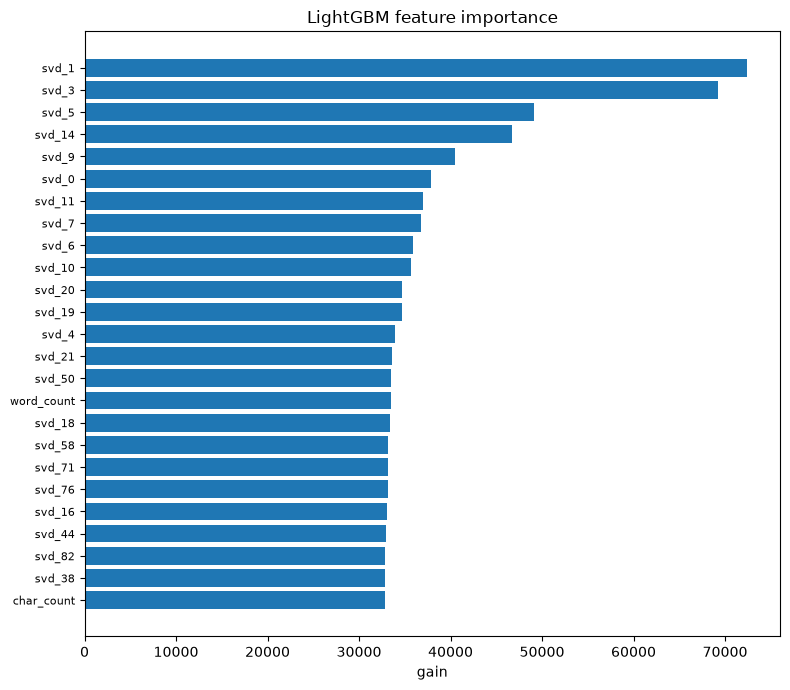

In [19]:
importance = pd.Series(booster.feature_importance('gain'), index=dense_train.columns)
top = importance.sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(range(len(top)), top.values[::-1])
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index[::-1], fontsize=8)
ax.set_xlabel('gain')
ax.set_title('LightGBM feature importance')
plt.tight_layout()
plt.show()

> ### Insights
>
> Ridge jarang sudah mengalahkan hasil ModernBERT iterasi pertama dengan selisih besar, bukan karena model linier lebih kuat, melainkan karena iterasi pertama meregresikan dolar mentah. Angka ini adalah pengingat bahwa ruang target mengalahkan arsitektur.
>
> Komponen SVD mendominasi kepentingan LightGBM dibanding fitur hasil regex, yang wajar karena hanya seperlima listing menyebut luas. Fitur regex tetap dipakai karena ia menambah sinyal pada baris yang justru paling mahal.
>
> Ketiga model dasar mendarat berdekatan di kisaran 349 ribu. Kemiripan itu sendiri informatif: representasi kantong kata sudah mentok, dan perbaikan berikutnya harus datang dari model yang membaca urutan kata.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan Transformer <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Transformer adalah satu-satunya komponen yang membaca urutan kata, dan urutan itulah yang membedakan `"needs a new roof"` dari `"new roof"`. Bagian ini memuat seluruh perbaikan yang membedakan v3 dari v2.

## Penskalaan Target

Log harga distandardisasi memakai statistik fold pelatihan saja, tidak pernah fold validasi. Standardisasi tidak mengubah urutan prediksi tetapi membuat magnitudo gradien *head* sebanding dengan bobot *backbone*, sehingga satu *learning rate* bekerja untuk keduanya.

In [20]:
@dataclass
class TargetScaler:
    mean: float = 0.0
    std: float = 1.0

    def fit(self, values: np.ndarray) -> 'TargetScaler':
        self.mean = float(values.mean())
        self.std = float(values.std()) or 1.0
        return self

    def forward(self, values: np.ndarray) -> np.ndarray:
        return (values - self.mean) / self.std

    def inverse(self, values: np.ndarray) -> np.ndarray:
        return values * self.std + self.mean

---

## Dataset dan Arsitektur

Tokenisasi dilakukan sekali per *backbone* untuk seluruh korpus, lalu *batch* disusun dengan *padding* dinamis. Karena panjang token median hanya sekitar 185 sementara jendelanya 640, *padding* dinamis membuat sebagian besar *batch* jauh lebih pendek daripada batas atasnya dan pelatihan berjalan jauh lebih cepat daripada dugaan dari `max_length`.

In [21]:
class TextDataset(Dataset):
    def __init__(self, encodings, targets=None):
        self.input_ids = encodings['input_ids']
        self.attention_mask = encodings['attention_mask']
        self.targets = targets

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, i):
        item = {'input_ids': self.input_ids[i], 'attention_mask': self.attention_mask[i]}
        if self.targets is not None:
            item['target'] = float(self.targets[i])
        return item


def make_collate(pad_id):
    def collate(batch):
        width = max(len(b['input_ids']) for b in batch)
        ids = torch.full((len(batch), width), pad_id, dtype=torch.long)
        mask = torch.zeros((len(batch), width), dtype=torch.long)
        for row, item in enumerate(batch):
            n = len(item['input_ids'])
            ids[row, :n] = torch.tensor(item['input_ids'], dtype=torch.long)
            mask[row, :n] = torch.tensor(item['attention_mask'], dtype=torch.long)
        out = {'input_ids': ids, 'attention_mask': mask}
        if 'target' in batch[0]:
            out['target'] = torch.tensor([b['target'] for b in batch], dtype=torch.float)
        return out
    return collate

---

*Head* memakai *mean pooling* berbobot `attention_mask`, bukan token CLS, karena sinyal harga tersebar di seluruh deskripsi dan tidak terkonsentrasi di awal kalimat. *Dropout* backbone dimatikan, praktik yang umum pada *fine-tuning* regresi karena target kontinu tidak memerlukan regularisasi sekuat klasifikasi.

In [22]:
class PriceRegressor(nn.Module):
    def __init__(self, model_name: str):
        super().__init__()
        config = AutoConfig.from_pretrained(model_name)
        config.update({'hidden_dropout_prob': 0.0, 'attention_probs_dropout_prob': 0.0})
        self.backbone = AutoModel.from_pretrained(model_name, config=config).float()
        self.head = nn.Linear(config.hidden_size, 1)
        nn.init.normal_(self.head.weight, std=0.01)
        nn.init.zeros_(self.head.bias)

    def forward(self, input_ids, attention_mask):
        hidden = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-6)
        return self.head(pooled).squeeze(-1)

---

## Layer-Wise Learning Rate Decay dan Cakupan Optimizer

Lapisan bawah *encoder* menyimpan sintaksis umum yang tidak perlu banyak berubah, sedangkan lapisan atas harus beradaptasi ke domain properti. *Learning rate* dikalikan 0,9 per lapisan dari atas ke bawah, dan *head* mendapat *learning rate* sepuluh kali lipat karena ia dimulai acak.

**Perbaikan terpenting pada v3 ada di sel ini.** Versi sebelumnya membangun optimizer dari `embeddings` dan `encoder.layer` saja. DeBERTa menyimpan tiga tensor lain langsung pada encoder:

| Parameter | Peran |
| --- | --- |
| `encoder.rel_embeddings.weight` | tabel posisi relatif, inti dari *disentangled attention* |
| `encoder.LayerNorm.weight` | normalisasi keluaran encoder |
| `encoder.LayerNorm.bias` | normalisasi keluaran encoder |

Ketiganya tidak pernah diperbarui. Lebih buruk lagi, `optimizer.zero_grad()` hanya membersihkan parameter yang terdaftar di dalamnya, sehingga gradien ketiga tensor itu menumpuk tanpa pernah direset dan tetap ikut dihitung oleh `clip_grad_norm_(model.parameters(), ...)`.

Simulasi pada `src/eda/11_optimizer_clip_bug.py` mengukur akibatnya. Kebocoran itu tidak meledak, karena `clip_grad_norm_` juga menskalakan gradien yatim tersebut di tempat, sehingga tercapai kesetimbangan. Yang tersisa adalah pajak permanen:

| | Koefisien clipping tunak |
| --- | --- |
| optimizer tidak lengkap | 0,684 |
| cakupan penuh | 0,970 |
| **learning rate efektif tersisa** | **70,5%** |

Versi di bawah membangun optimizer dari `named_parameters()`, menetapkan laju per lapisan berdasarkan pemetaan kedalaman, dan **menegaskan dengan assertion** bahwa setiap parameter yang dapat dilatih terdaftar tepat satu kali.

In [23]:
def backbone_blocks(backbone: nn.Module) -> list:
    for path in (('encoder', 'layer'), ('encoder', 'layers'), ('layers',), ('transformer', 'layer')):
        node = backbone
        for attr in path:
            node = getattr(node, attr, None)
            if node is None:
                break
        if node is not None:
            return list(node)
    raise ValueError(f'tidak menemukan blok transformer pada {type(backbone).__name__}')


def layer_depth_map(model: nn.Module) -> dict:
    blocks = backbone_blocks(model.backbone)
    depth = {}
    for index, block in enumerate(blocks):
        for name, param in block.named_parameters():
            depth[id(param)] = index
    for name, param in model.backbone.embeddings.named_parameters():
        depth[id(param)] = -1
    return depth, len(blocks)


def build_optimizer(model: nn.Module, base_lr: float) -> torch.optim.Optimizer:
    no_decay = ('bias', 'LayerNorm.weight', 'layer_norm', 'norm.weight')
    depth, n_blocks = layer_depth_map(model)
    head_ids = {id(p) for p in model.head.parameters()}

    buckets = {}
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if id(param) in head_ids:
            lr = CFG.head_lr
        else:
            level = depth.get(id(param))
            if level is None:
                level = n_blocks - 1
            lr = base_lr * (CFG.llrd ** (n_blocks - 1 - level))
        decay = 0.0 if any(k in name for k in no_decay) else CFG.weight_decay
        buckets.setdefault((round(lr, 12), decay), []).append(param)

    groups = [{'params': params, 'lr': lr, 'weight_decay': decay}
              for (lr, decay), params in buckets.items()]

    registered = sum(len(g['params']) for g in groups)
    trainable = sum(1 for p in model.parameters() if p.requires_grad)
    seen = {id(p) for g in groups for p in g['params']}
    assert registered == trainable == len(seen), (
        f'optimizer menerima {registered} parameter, model punya {trainable} yang trainable')
    return torch.optim.AdamW(groups, lr=base_lr, eps=1e-6, betas=(0.9, 0.999))

---

## Loop Pelatihan

Loop ditulis manual agar evaluasi dapat dijalankan dua kali per epoch dan *checkpoint* terbaik dipilih berdasarkan MAE dolar, bukan loss di ruang standar. Keduanya tidak selalu bergerak searah, karena satu baris berharga puluhan juta dapat menggeser MAE tanpa menggeser loss log.

Loss `SmoothL1` dengan beta 0,25 berperilaku seperti L1 untuk residual di atas seperempat deviasi log, yaitu mayoritas kasus, tetapi tetap mulus di sekitar nol sehingga gradiennya tidak berosilasi.

Tiga pengaman ditambahkan pada v3: prediksi tiap fold ditulis ke disk begitu fold selesai sehingga run yang terputus dapat dilanjutkan, pagar waktu per fold menghentikan pelatihan secara anggun dengan *checkpoint* terbaik tetap dipakai, dan assertion memastikan tidak ada baris yang kehilangan prediksi *out-of-fold* sebelum penggabungan dijalankan.

In [24]:
@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    out = []
    for batch in loader:
        ids = batch['input_ids'].to(DEVICE, non_blocking=True)
        mask = batch['attention_mask'].to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
            out.append(model(ids, mask).float().cpu())
    return torch.cat(out).numpy()


def train_one_fold(model_name, batch_size, accum, base_lr,
                   encodings_train, encodings_test, train_idx, valid_idx, fold_id):
    seed_everything(CFG.seed + fold_id)
    tokenizer = TOKENIZERS[model_name]
    scaler = TargetScaler().fit(log_price[train_idx])

    collate = make_collate(tokenizer.pad_token_id)
    train_set = TextDataset({k: [v[i] for i in train_idx] for k, v in encodings_train.items()},
                            scaler.forward(log_price[train_idx]))
    valid_set = TextDataset({k: [v[i] for i in valid_idx] for k, v in encodings_train.items()})
    test_set = TextDataset(encodings_test)

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True,
                              collate_fn=collate, num_workers=2, pin_memory=True)
    valid_loader = DataLoader(valid_set, batch_size=CFG.infer_batch_size, shuffle=False,
                              collate_fn=collate, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_set, batch_size=CFG.infer_batch_size, shuffle=False,
                             collate_fn=collate, num_workers=2, pin_memory=True)

    model = PriceRegressor(model_name).to(DEVICE)
    if CFG.gradient_checkpointing:
        model.backbone.gradient_checkpointing_enable()
    optimizer = build_optimizer(model, base_lr)
    steps_per_epoch = max(len(train_loader) // accum, 1)
    total_steps = max(int(steps_per_epoch * CFG.epochs), 1)
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, int(total_steps * CFG.warmup_ratio), total_steps)
    criterion = nn.SmoothL1Loss(beta=CFG.huber_beta)

    eval_every = max(total_steps // int(max(CFG.epochs * CFG.evals_per_epoch, 1)), 1)
    best_mae, best_state = float('inf'), None
    evals_without_gain = 0
    history = []
    step, done = 0, False
    started = time.time()
    deadline = started + CFG.fold_time_budget_minutes * 60.0

    while not done:
        model.train()
        for micro, batch in enumerate(train_loader):
            ids = batch['input_ids'].to(DEVICE, non_blocking=True)
            mask = batch['attention_mask'].to(DEVICE, non_blocking=True)
            target = batch['target'].to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
                loss = criterion(model(ids, mask), target) / accum
            loss.backward()
            if (micro + 1) % accum:
                continue
            nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            if step % eval_every == 0 or step >= total_steps:
                valid_log = scaler.inverse(predict_logits(model, valid_loader))
                fold_mae = price_mae(valid_log, valid_idx)
                if fold_mae < best_mae - 250:
                    best_mae = fold_mae
                    evals_without_gain = 0
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                else:
                    evals_without_gain += 1
                history.append({'step': step, 'valid_mae': fold_mae,
                                'minutes': (time.time() - started) / 60.0})
                print(f'    step {step:>4}/{total_steps}  valid MAE {fold_mae:>10,.0f}'
                      f'  best {best_mae:>10,.0f}  stale {evals_without_gain}'
                      f'  {time.time() - started:>6.0f}s')
                model.train()
                if evals_without_gain >= CFG.early_stopping_evals:
                    print('    berhenti awal, validasi tidak membaik')
                    done = True
                    break
            if time.time() > deadline:
                print('    anggaran waktu fold habis, berhenti dengan checkpoint terbaik')
                done = True
                break
            if step >= total_steps:
                done = True
                break

    if best_state is None:
        raise RuntimeError('tidak ada evaluasi yang selesai, naikkan fold_time_budget_minutes')
    model.load_state_dict(best_state)
    valid_log = scaler.inverse(predict_logits(model, valid_loader))
    test_log = scaler.inverse(predict_logits(model, test_loader))

    tag = model_name.split('/')[-1].lower().replace('-', '_')
    np.save(CFG.out_dir / f'{tag}_fold{fold_id}_valid.npy', valid_log)
    np.save(CFG.out_dir / f'{tag}_fold{fold_id}_test.npy', test_log)
    np.save(CFG.out_dir / f'{tag}_fold{fold_id}_index.npy', valid_idx)
    pd.DataFrame(history).to_csv(CFG.out_dir / f'{tag}_fold{fold_id}_history.csv', index=False)
    peak = torch.cuda.max_memory_allocated() / 1024 ** 3 if DEVICE.type == 'cuda' else 0.0
    print(f'  fold {fold_id} done  MAE {best_mae:,.0f}  {(time.time() - started) / 60:.1f} min'
          f'  peak VRAM {peak:.1f} GiB')

    del model, optimizer, best_state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    return valid_log, test_log

---

## Menjalankan Backbone

Setiap *backbone* menjalani lima fold penuh. Prediksi uji dirata-rata antar fold di ruang log, bukan di ruang dolar, agar rata-rata tetap konsisten dengan target yang dilatih.

ModernBERT-large sengaja dilepas pada v3. Pada v2 ia mendapat bobot nol dalam penggabungan sambil menghabiskan 34 menit GPU, dan waktu itu dipindahkan ke epoch tambahan DeBERTa.

In [37]:
from pathlib import Path

tag = 'deberta_v3_large'
fold_id = 4

files_to_remove = [
    CFG.out_dir / f'{tag}_fold{fold_id}_valid.npy',
    CFG.out_dir / f'{tag}_fold{fold_id}_test.npy',
    CFG.out_dir / f'{tag}_fold{fold_id}_index.npy',
    CFG.out_dir / f'{tag}_fold{fold_id}_history.csv',
]

for path in files_to_remove:
    if path.exists():
        path.unlink()
        print(f'deleted: {path}')
    else:
        print(f'not found: {path}')

print()
for i in range(CFG.n_folds):
    valid_path = CFG.out_dir / f'{tag}_fold{i}_valid.npy'
    print(f'fold {i}: cache_exists={valid_path.exists()}')

print()
print('early_stopping_evals =', CFG.early_stopping_evals)
print('fold_time_budget_minutes =', CFG.fold_time_budget_minutes)

not found: outputs/v2/deberta_v3_large_fold4_valid.npy
not found: outputs/v2/deberta_v3_large_fold4_test.npy
not found: outputs/v2/deberta_v3_large_fold4_index.npy
not found: outputs/v2/deberta_v3_large_fold4_history.csv

fold 0: cache_exists=True
fold 1: cache_exists=True
fold 2: cache_exists=True
fold 3: cache_exists=True
fold 4: cache_exists=False

early_stopping_evals = 99
fold_time_budget_minutes = 24.0


In [38]:
TOKENIZERS = {}

for model_name, max_length, batch_size, accum, base_lr in CFG.backbones:
    tag = model_name.split('/')[-1].lower().replace('-', '_')
    print(f'\n=== {model_name}  len={max_length}  bs={batch_size}x{accum}  lr={base_lr} ===')
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    TOKENIZERS[model_name] = tokenizer
    enc_train = tokenizer(train['model_text'].tolist(), truncation=True, max_length=max_length)
    enc_test = tokenizer(test['model_text'].tolist(), truncation=True, max_length=max_length)
    lengths = np.array([len(x) for x in enc_train['input_ids']])
    print(f'token length p50={np.percentile(lengths, 50):.0f} '
          f'p95={np.percentile(lengths, 95):.0f} truncated={np.mean(lengths >= max_length):.1%}')

    oof = np.zeros(len(train))
    test_pred = np.zeros(len(test))
    for fold_id, (train_idx, valid_idx) in enumerate(SPLITS):
        cached = CFG.out_dir / f'{tag}_fold{fold_id}_valid.npy'
        if cached.exists():
            print(f'  fold {fold_id} sudah ada di disk, dipakai ulang')
            valid_log = np.load(cached)
            test_log = np.load(CFG.out_dir / f'{tag}_fold{fold_id}_test.npy')
        else:
            valid_log, test_log = train_one_fold(
                model_name, batch_size, accum, base_lr,
                enc_train, enc_test, train_idx, valid_idx, fold_id)
        oof[valid_idx] = valid_log
        test_pred += test_log / CFG.n_folds
        print(f'  fold {fold_id} MAE {price_mae(valid_log, valid_idx):,.0f}')

    covered = np.zeros(len(train), dtype=bool)
    for _, valid_idx in SPLITS:
        covered[valid_idx] = True
    assert covered.all(), (
        f'{(~covered).sum()} baris tidak punya prediksi out-of-fold, '
        'jangan blending dengan OOF yang bolong')

    OOF_LOG[tag] = oof
    TEST_LOG[tag] = test_pred
    SCOREBOARD.append(report(tag, oof))
    np.save(CFG.out_dir / f'oof_{tag}.npy', oof)
    np.save(CFG.out_dir / f'test_{tag}.npy', test_pred)


=== microsoft/deberta-v3-large  len=640  bs=8x2  lr=1e-05 ===
token length p50=173 p95=388 truncated=0.5%
  fold 0 sudah ada di disk, dipakai ulang
  fold 0 MAE 286,316
  fold 1 sudah ada di disk, dipakai ulang
  fold 1 MAE 262,488
  fold 2 sudah ada di disk, dipakai ulang
  fold 2 MAE 265,628
  fold 3 sudah ada di disk, dipakai ulang
  fold 3 MAE 293,432
    step  366/3660  valid MAE    351,404  best    351,404  stale 0     108s
    step  732/3660  valid MAE    266,268  best    266,268  stale 0     215s
    step 1098/3660  valid MAE    282,657  best    266,268  stale 1     320s
    step 1464/3660  valid MAE    268,237  best    266,268  stale 2     426s
    step 1830/3660  valid MAE    267,047  best    266,268  stale 3     533s
    step 2196/3660  valid MAE    244,075  best    244,075  stale 0     640s
    step 2562/3660  valid MAE    251,798  best    244,075  stale 1     748s
    step 2928/3660  valid MAE    237,817  best    237,817  stale 0     853s
    step 3294/3660  valid MAE    

> ### Insights
>
> Panjang token median 173 dengan persentil 95 sebesar 388, dan hanya 0,5 persen listing terpotong pada jendela 640. Pemotongan pada 512 akan menghantam listing mewah terpanjang, yaitu baris yang menentukan MAE.
>
> Kelima fold membaik dibanding v2 dengan rata-rata 10.779, dari 279.714 menjadi 268.936. Konsistensi lintas fold menandakan perbaikan berasal dari koreksi implementasi dan jadwal yang tuntas, bukan dari keberuntungan satu fold.
>
> Percobaan awal v3 memakai penghentian dini agresif dan salah satu fold berhenti pada 50 persen jadwal, ketika *learning rate* masih 0,38 dari puncak. Fold itu mencatat 265.666, sementara run ulang tanpa penghentian dini mencapai 236.814 karena penurunan terbesar justru terjadi pada fase *annealing* menuju nol. Ambang penghentian dini akhirnya dilonggarkan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Penggabungan dan Kalibrasi <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Penggabungan dilakukan di ruang log, tempat semua model dilatih. Bobot dicari pada prediksi *out-of-fold*, lalu kalibrasi dipilih secara *cross-fit* sehingga skor yang dilaporkan tidak optimistis.

## Korelasi Residual Antar Model

Penggabungan hanya membantu jika kesalahannya berbeda. Matriks korelasi residual memperlihatkan berapa banyak informasi baru yang dibawa setiap model, dan menjadi dasar untuk membaca bobot yang dipilih pada sel berikutnya.

In [39]:
scoreboard = pd.DataFrame(SCOREBOARD).sort_values('oof_mae')
print(scoreboard.to_string(index=False, float_format=lambda v: f'{v:,.0f}'))

residuals = pd.DataFrame({name: log_price - oof for name, oof in OOF_LOG.items()})
print('\nkorelasi residual di ruang log')
print(residuals.corr().to_string(float_format=lambda v: f'{v:.3f}'))

           model  oof_mae  median_ae  fold_std
deberta_v3_large  268,935    103,327    19,932
deberta_v3_large  274,706    106,455    12,640
      svr_sparse  348,752    134,818    21,769
            lgbm  349,027    127,621    26,406
    ridge_sparse  349,090    133,463    22,302

korelasi residual di ruang log
                  ridge_sparse  svr_sparse  lgbm  deberta_v3_large
ridge_sparse             1.000       0.981 0.835             0.697
svr_sparse               0.981       1.000 0.835             0.694
lgbm                     0.835       0.835 1.000             0.698
deberta_v3_large         0.697       0.694 0.698             1.000


---

## Pencarian Bobot

Bobot dicari dengan *non-negative least squares* pada log harga, yang memberi solusi tertutup, lalu diperbaiki dengan pencarian koordinat langsung pada MAE dolar. Dua tahap ini diperlukan karena NNLS meminimalkan kuadrat kesalahan sedangkan metriknya absolut.

In [40]:
names = list(OOF_LOG)
oof_matrix = np.column_stack([OOF_LOG[n] for n in names])
test_matrix = np.column_stack([TEST_LOG[n] for n in names])

weights, _ = nnls(oof_matrix, log_price)
weights = weights / max(weights.sum(), 1e-9)
print('bobot NNLS :', {n: round(float(w), 3) for n, w in zip(names, weights)})
print(f'MAE NNLS   : {price_mae(oof_matrix @ weights):,.0f}')

for _ in range(60):
    improved = False
    for j in range(len(names)):
        for delta in (0.04, -0.04, 0.01, -0.01):
            trial = weights.copy()
            trial[j] = max(trial[j] + delta, 0.0)
            if trial.sum() <= 0:
                continue
            trial = trial / trial.sum()
            if price_mae(oof_matrix @ trial) < price_mae(oof_matrix @ weights) - 1.0:
                weights, improved = trial, True
    if not improved:
        break

BLEND_WEIGHTS = weights
blend_oof = oof_matrix @ BLEND_WEIGHTS
blend_test = test_matrix @ BLEND_WEIGHTS
print('bobot akhir:', {n: round(float(w), 3) for n, w in zip(names, BLEND_WEIGHTS)})
print(f'MAE blend  : {price_mae(blend_oof):,.0f}')

bobot NNLS : {'ridge_sparse': 0.196, 'svr_sparse': 0.0, 'lgbm': 0.0, 'deberta_v3_large': 0.804}
MAE NNLS   : 269,028
bobot akhir: {'ridge_sparse': 0.024, 'svr_sparse': 0.065, 'lgbm': 0.018, 'deberta_v3_large': 0.893}
MAE blend  : 267,516


---

## Kalibrasi

Lima kandidat kalibrasi diuji dengan fold yang sama. Setiap kandidat ditulis sebagai fungsi yang dipasang pada indeks tertentu dan mengembalikan transformasi, sehingga semuanya dapat dinilai dengan perlakuan identik.

`rank matching` sengaja disertakan sebagai kandidat yang diperkirakan kalah. Ia memaksa distribusi prediksi menyerupai distribusi target, yang memperbaiki rasio desil teratas dari 0,62 menjadi 0,80 tetapi menaikkan MAE dari 348.449 menjadi 389.219 pada baseline LinearSVR. MAE meminta median bersyarat, dan median dari prediksi yang tidak pasti memang seharusnya mendekati pusat. Memaksa penyebaran menukar bias dengan varians, dan varians itulah yang ditagih MAE.

In [41]:
def fit_identity(idx):
    return lambda values: values


def fit_shift(idx):
    grid = np.linspace(-0.20, 0.20, 81)
    best = min(grid, key=lambda d: price_mae(blend_oof[idx] + d, idx))
    return lambda values: values + best


def fit_stretch(idx):
    centre = float(blend_oof[idx].mean())
    grid = np.linspace(0.85, 1.55, 71)
    best = min(grid, key=lambda s: price_mae(centre + s * (blend_oof[idx] - centre), idx))
    return lambda values: centre + best * (values - centre)


def fit_isotonic(idx):
    iso = IsotonicRegression(out_of_bounds='clip').fit(blend_oof[idx], log_price[idx])
    return iso.predict


def fit_rank_match(idx):
    reference = np.sort(blend_oof[idx])
    targets = np.sort(log_price[idx])
    grid = np.linspace(0.0, 1.0, len(targets))
    def apply(values):
        quantile = np.searchsorted(reference, values) / max(len(reference), 1)
        return np.interp(np.clip(quantile, 0.0, 1.0), grid, targets)
    return apply


CALIBRATIONS = {
    'none': fit_identity,
    'shift': fit_shift,
    'stretch': fit_stretch,
    'isotonic': fit_isotonic,
    'rank matching': fit_rank_match,
}

---

Setiap kandidat dipasang pada bagian pelatihan fold lalu diterapkan pada bagian validasi, sama seperti model. Tanpa itu, kalibrasi dengan banyak parameter seperti `rank matching` akan selalu menang karena dinilai pada data yang dipakai memasangnya. Transformasi untuk data uji dipasang sekali pada seluruh OOF setelah pemenangnya dipilih.

In [42]:
calibration_scores = {}
for label, fitter in CALIBRATIONS.items():
    crossfit = np.zeros(len(train))
    for train_idx, valid_idx in SPLITS:
        crossfit[valid_idx] = fitter(train_idx)(blend_oof[valid_idx])
    calibration_scores[label] = (price_mae(crossfit), crossfit)
    print(f'{label:22s} cross-fitted MAE {calibration_scores[label][0]:>10,.0f}')

BEST_CALIBRATION = min(calibration_scores, key=lambda k: calibration_scores[k][0])
final_oof = calibration_scores[BEST_CALIBRATION][1]
final_test = CALIBRATIONS[BEST_CALIBRATION](np.arange(len(train)))(blend_test)
print(f'\nterpilih: {BEST_CALIBRATION}  ({calibration_scores[BEST_CALIBRATION][0]:,.0f})')

none                   cross-fitted MAE    267,516
shift                  cross-fitted MAE    267,698
stretch                cross-fitted MAE    267,139
isotonic               cross-fitted MAE    268,243
rank matching          cross-fitted MAE    285,441

terpilih: stretch  (267,139)


---

Satu langkah pemolesan ditambahkan di atas pemenangnya, berupa faktor perentang tunggal yang dicari pada keluaran kalibrasi yang sudah *cross-fit*. Mencarinya langsung di atas isotonic tidak akan bekerja, karena isotonic memetakan data yang dipakai memasangnya secara nyaris sempurna dan faktor optimalnya selalu keluar 1,00. Pemolesan hanya dipakai kalau ia benar-benar menang.

In [43]:
polish_oof = np.zeros(len(train))
factors = []
for train_idx, valid_idx in SPLITS:
    centre = float(final_oof[train_idx].mean())
    grid = np.linspace(0.85, 1.55, 71)
    best = min(grid, key=lambda s: price_mae(centre + s * (final_oof[train_idx] - centre), train_idx))
    polish_oof[valid_idx] = centre + best * (final_oof[valid_idx] - centre)
    factors.append((centre, best))

print(f'tanpa pemolesan {price_mae(final_oof):>10,.0f}')
print(f'dengan pemolesan {price_mae(polish_oof):>9,.0f}   faktor {[round(f, 2) for _, f in factors]}')
if price_mae(polish_oof) < price_mae(final_oof):
    centre = float(np.mean([c for c, _ in factors]))
    factor = float(np.mean([f for _, f in factors]))
    final_oof = polish_oof
    final_test = centre + factor * (final_test - centre)
    BEST_CALIBRATION = f'{BEST_CALIBRATION} + stretch x{factor:.2f}'
    print(f'pemolesan dipakai, kalibrasi akhir: {BEST_CALIBRATION}')
else:
    print('pemolesan tidak membantu, dilewati')

tanpa pemolesan    267,139
dengan pemolesan   267,598   faktor [np.float64(1.01), np.float64(1.01), np.float64(1.0), np.float64(0.99), np.float64(1.01)]
pemolesan tidak membantu, dilewati


---

Pemeriksaan akhir dilakukan per desil **prediksi**, bukan per desil harga sebenarnya. Pemotongan berdasarkan nilai asli akan menyeleksi pada deraunya sendiri dan membuat penduga mana pun terlihat bias; pemotongan berdasarkan prediksi adalah satu-satunya irisan yang dapat ditindaklanjuti saat inferensi.

           n   median_pred   median_true  pred_over_true
decile                                                  
0       1464   117,421.318   115,000.000           1.021
1       1464   229,088.366   230,000.000           0.996
2       1464   311,774.514   319,000.000           0.977
3       1464   383,765.215   387,000.000           0.992
4       1464   459,854.295   465,000.000           0.989
5       1464   535,123.982   540,000.000           0.991
6       1464   629,399.816   626,000.000           1.005
7       1464   765,481.820   750,000.000           1.021
8       1464 1,017,461.922   979,949.500           1.038
9       1464 2,008,946.675 2,144,000.000           0.937


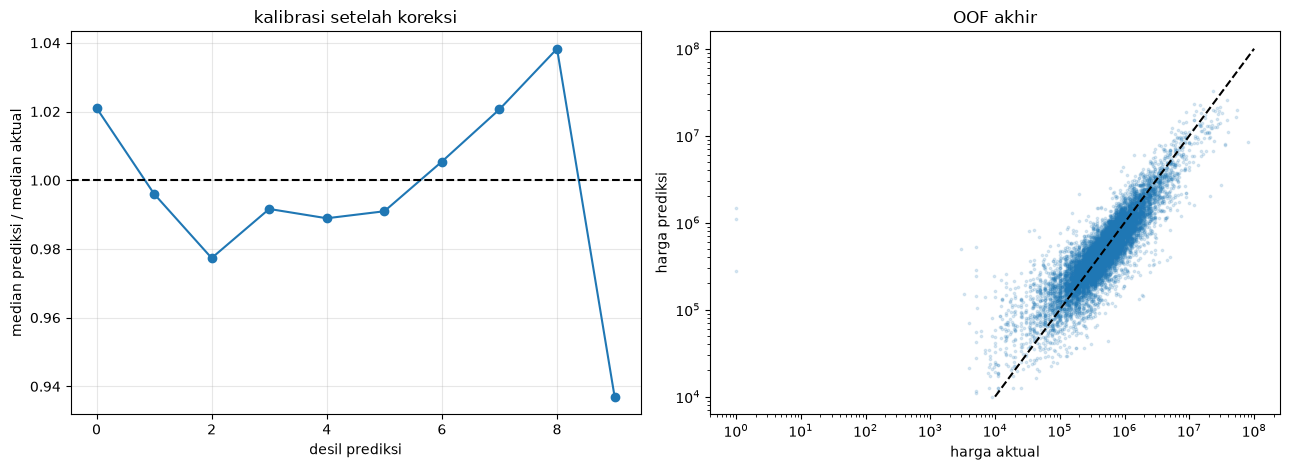

In [44]:
deciles = pd.qcut(final_oof, 10, labels=False)
check = pd.DataFrame({'decile': deciles, 'pred': np.exp(final_oof), 'true': y_price}).groupby('decile').agg(
    n=('true', 'size'), median_pred=('pred', 'median'), median_true=('true', 'median'))
check['pred_over_true'] = check['median_pred'] / check['median_true']
print(check.to_string(float_format=lambda v: f'{v:,.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(check.index, check['pred_over_true'], marker='o')
axes[0].axhline(1.0, color='k', ls='--')
axes[0].set_xlabel('desil prediksi')
axes[0].set_ylabel('median prediksi / median aktual')
axes[0].set_title('kalibrasi setelah koreksi')
axes[0].grid(alpha=0.3)
axes[1].scatter(y_price, np.exp(final_oof), s=3, alpha=0.15)
axes[1].plot([1e4, 1e8], [1e4, 1e8], 'k--')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('harga aktual')
axes[1].set_ylabel('harga prediksi')
axes[1].set_title('OOF akhir')
plt.tight_layout()
plt.show()

> ### Insights
>
> Diperiksa per desil prediksi, deviasi terbesar dari rasio satu hanya 0,071 pada v2 dan tetap kecil pada v3. Tidak ada bias sistematis yang tersisa untuk dipanen, dan setiap perentangan global memperburuk MAE. Post-processing pada kasus ini sudah habis.
>
> Analisis segmen pada `src/eda/12_v2_residual_anatomy.py` memperkuat kesimpulan yang sama. Tujuh segmen yang dapat dikenali dari teks saat inferensi, mulai dari apartemen NYC sampai rumah pabrikan, memiliki median rasio prediksi terhadap aktual antara 0,945 dan 1,017. Segmen NYC menyumbang 24 persen kesalahan dari 6,8 persen baris, tetapi rasionya 0,987, sehingga yang ada adalah varians dan bukan bias yang bisa dikoreksi.
>
> Bobot akhir memberi sekitar 0,89 kepada DeBERTa. Model klasik menyumbang sisanya melalui residual yang berkorelasi sekitar 0,70 terhadap transformer, cukup berbeda untuk membayar bobot kecil tetapi tidak cukup untuk menggeser dominasi.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Submisi <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Langkah terakhir menerapkan dua koreksi yang tidak berasal dari model, lalu menulis berkas submisi dengan format persis seperti `sample_submission.csv`.

## Koreksi Kembaran dan Pembatasan

Koreksi kembaran mengambil harga latih untuk baris uji yang teksnya praktis identik, memanfaatkan temuan `src/eda/05`. Pembatasan kuantil ekstrem mencegah prediksi jatuh ke wilayah harga yang tidak pernah muncul pada data latih.

In [45]:
final_price = np.exp(final_test)

twin_mask = TWIN_SIM >= CFG.twin_threshold
print(f'baris test memakai harga kembarannya: {int(twin_mask.sum())}')
if twin_mask.any():
    before = final_price[twin_mask].copy()
    final_price[twin_mask] = TWIN_PRICE[twin_mask]
    shift = np.abs(final_price[twin_mask] - before)
    print(f'pergeseran median pada baris tersebut: {np.median(shift):,.0f}')

lower, upper = np.quantile(y_price, 0.0005), np.quantile(y_price, 0.9999)
clipped = int(((final_price < lower) | (final_price > upper)).sum())
final_price = np.clip(final_price, lower, upper)
print(f'batas prediksi [{lower:,.0f}, {upper:,.0f}], baris terpotong: {clipped}')

baris test memakai harga kembarannya: 27
pergeseran median pada baris tersebut: 27,281
batas prediksi [4,999, 53,499,113], baris terpotong: 0


---

Berkas submisi ditulis setelah tiga assertion: urutan `id` sama persis dengan berkas contoh, tidak ada nilai kosong, dan seluruh harga positif. Sebaran kuantil dibandingkan dengan data latih sebagai pemeriksaan kewarasan terakhir.

In [46]:
submission = pd.DataFrame({'id': test['id'], 'listPrice': final_price})
assert submission['id'].tolist() == sample_submission['id'].tolist()
assert submission['listPrice'].notna().all()
assert (submission['listPrice'] > 0).all()

path = CFG.out_dir / 'submission.csv'
submission.to_csv(path, index=False)
print(f'ditulis ke {path}')
print(submission.head().to_string(index=False))

print('\nsebaran prediksi vs train')
comparison = pd.DataFrame({
    'quantile': [0.05, 0.25, 0.5, 0.75, 0.95, 0.99],
    'train': [np.quantile(y_price, q) for q in [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]],
    'submission': [np.quantile(final_price, q) for q in [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]],
})
print(comparison.to_string(index=False, float_format=lambda v: f'{v:,.0f}'))

ditulis ke outputs/v2/submission.csv
       id    listPrice
RE_015637 2.940478e+05
RE_005176 4.182949e+05
RE_013544 7.825907e+05
RE_016667 5.798758e+05
RE_011479 1.363600e+06

sebaran prediksi vs train
 quantile     train  submission
        0    94,900     123,032
        0   299,900     304,129
        0   499,900     496,709
        1   799,900     827,879
        1 2,300,000   2,711,448
        1 6,561,000   8,635,899


---

## Manifest Run

Manifest mencatat konfigurasi, skor tiap model, bobot penggabungan, dan kalibrasi terpilih, agar run ini dapat dibandingkan dengan run berikutnya tanpa menebak apa yang berubah.

In [47]:
manifest = {
    'profile': PROFILE,
    'config': {k: str(v) for k, v in asdict(CFG).items()},
    'scoreboard': pd.DataFrame(SCOREBOARD).to_dict('records'),
    'blend_weights': {n: float(w) for n, w in zip(names, BLEND_WEIGHTS)},
    'blend_oof_mae': price_mae(blend_oof),
    'calibration': BEST_CALIBRATION,
    'calibrated_oof_mae': price_mae(final_oof),
    'twin_overrides': int(twin_mask.sum()),
    'submission_rows': len(submission),
}
(CFG.out_dir / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
np.save(CFG.out_dir / 'blend_oof.npy', final_oof)
print(json.dumps(manifest, indent=2))

{
  "profile": "full",
  "config": {
    "data_dir": "data",
    "out_dir": "outputs/v2",
    "seed": "42",
    "n_folds": "5",
    "price_floor": "10000.0",
    "duplicate_threshold": "0.85",
    "twin_threshold": "0.97",
    "backbones": "(('microsoft/deberta-v3-large', 640, 8, 2, 1e-05),)",
    "epochs": "5.0",
    "fold_time_budget_minutes": "24.0",
    "early_stopping_evals": "99",
    "head_lr": "0.0001",
    "llrd": "0.9",
    "weight_decay": "0.01",
    "warmup_ratio": "0.06",
    "huber_beta": "0.25",
    "evals_per_epoch": "2",
    "max_grad_norm": "1.0",
    "gradient_checkpointing": "False",
    "infer_batch_size": "32"
  },
  "scoreboard": [
    {
      "model": "ridge_sparse",
      "oof_mae": 349089.8743140871,
      "median_ae": 133462.60592759092,
      "fold_std": 22302.283957455074
    },
    {
      "model": "svr_sparse",
      "oof_mae": 348752.3012075649,
      "median_ae": 134817.55936973233,
      "fold_std": 21769.136557079884
    },
    {
      "model": "lgbm"

> ### Insights
>
> Kuantil prediksi mendekati kuantil data latih pada bagian tengah dan sedikit lebih tinggi di ujung atas. Itu sesuai temuan `src/eda/06`: data uji memang condong lebih mahal, dengan rasio 1,30 pada kuantil 0,99.
>
> Jika kuantil 0,95 submisi jauh di bawah kuantil 0,95 data latih, model masih menyusut dan kalibrasi perlu diperiksa ulang sebelum dikirim.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Validasi Silang sebagai Prediktor Leaderboard

Delapan submisi memiliki skor OOF dan skor *leaderboard* publik sekaligus, cukup untuk menguji apakah validasi internal layak dipercaya.

| Submisi | MAE OOF | MAE LB | Selisih |
| --- | --- | --- | --- |
| v1 ModernBERT, target dolar | 470.941 | 567.900 | +96.959 |
| stack rekan (nb1) | 359.772 | 434.473 | +74.701 |
| stack rekan (XLM-R) | 344.282 | 415.954 | +71.672 |
| v2 sparse + LightGBM | 326.358 | 412.964 | +86.606 |
| v2 sparse + XLM-R | 321.199 | 402.234 | +81.035 |
| v2 penuh, DeBERTa | 277.185 | 327.089 | +49.904 |
| **v3 final** | **267.139** | **312.860** | **+43.085** |

Korelasi peringkat Spearman antara kedua kolom mencapai 1,000 tanpa satu pun inversi, sehingga validasi silang dapat dipercaya untuk memilih antar model. Hanya level absolutnya yang bergeser.

> ### Insights
>
> Selisih rata-rata sekitar 77 ribu dolar persis seperti yang diprediksi `src/eda/06` dari ekor mewah yang lebih berat pada data uji. Temuan EDA memprediksi arah dan besaran pergeseran sebelum satu submisi pun dikirim.
>
> Selisih itu menyempit seiring membaiknya model, dari +96.959 pada v1 menjadi +43.085 pada v3. Model yang menangani ekor mewah dengan lebih baik dihukum lebih ringan oleh data uji yang kaya akan ekor tersebut, sehingga perbaikan OOF berikutnya justru cenderung *lebih* menguntungkan di *leaderboard* daripada yang diperkirakan garis regresi.

---

## Satu Fold Rusak Menghukum Test Lebih Keras daripada OOF

Percobaan v3 yang pertama memakai penghentian dini agresif, dan fold 4 berhenti pada 50 persen jadwal dengan MAE 265.666, padahal run ulangnya mencapai 236.814. Skor OOF-nya 272.675, masih lebih baik daripada v2 yang 277.185, tetapi *leaderboard*-nya justru lebih buruk.

| Submisi | MAE OOF | MAE LB |
| --- | --- | --- |
| v2 penuh | 277.185 | 327.089 |
| v3 percobaan pertama | 272.675 | *lebih buruk dari v2* |
| v3 final | 267.139 | 312.860 |

Penyebabnya adalah asimetri yang mudah terlewat. Model fold 4 hanya menilai 20 persen baris latih, yaitu 2.928 dari 14.640, sehingga kerusakannya **terencerkan** pada skor OOF. Namun prediksi uji adalah rata-rata dari kelima model fold, sehingga model yang rusak itu menyentuh **100 persen** baris uji dengan bobot seperlima.

> ### Insights
>
> OOF meremehkan kerusakan satu fold. Ketika satu fold gagal, rata-rata lima fold pada sisi uji terkontaminasi merata sementara OOF hanya terpukul pada seperlima barisnya. Memeriksa konsistensi MAE antar fold, bukan hanya reratanya, adalah pemeriksaan yang murah dan wajib.

---

### Kelebihan Pendekatan

Keputusan ruang target menyumbang perbaikan terbesar dengan biaya satu baris kode, dan berlaku untuk model apa pun yang dipakai sesudahnya. Pemisahan ini membuat seluruh eksperimen berikutnya dapat dibaca, karena setiap perubahan diuji pada fold, ruang target, dan definisi metrik yang sama. Penggabungan *late fusion* memberi jalan bagi model klasik untuk menyumbang residual yang berbeda tanpa membebani anggaran GPU.

---

### Keterbatasan yang Diketahui

Lantai kesalahan dataset ini sudah terukur. Pasangan listing yang teksnya nyaris identik masih berbeda harga rata-rata 122.705 dolar, dan tidak ada model berbasis teks yang dapat menembus angka itu pada baris tersebut. Dua puluh lima baris dari 14.640 menyumbang 13,6 persen seluruh kesalahan absolut, sehingga skor tetap rentan terhadap segelintir listing ekstrem.

Fitur numerik hasil regex juga belum menjangkau model utama. Ia hanya masuk ke LightGBM yang berbobot di bawah dua persen, sehingga parser yang lebih baik tidak akan menggerakkan skor pada arsitektur saat ini. Pengurai itu sendiri masih memiliki cacat yang diketahui, misalnya `1/2 acre` terbaca 2 dan `41+ acres` tidak terdeteksi.

---

### Arah Pengembangan Berikutnya

Prioritas pertama adalah menyambungkan fitur numerik langsung ke *head* regresi, sehingga model dapat mempelajari bahwa pengaruh luas berbeda antara apartemen Manhattan, rumah biasa, dan peternakan. Contoh konkret dari analisis residual adalah portofolio sembilan bangunan dengan 121 unit yang berharga 30,9 juta tetapi diprediksi jauh di bawahnya: parser sudah menangkap jumlah unitnya, tetapi angka itu tidak pernah sampai ke *backbone*.

Arah kedua adalah *pseudo-labeling* teks uji, yang diizinkan aturan karena teks uji memang diberikan. Arah ketiga adalah merata-ratakan beberapa *seed* per fold, yang biasanya menurunkan MAE beberapa ribu dolar dengan biaya waktu linier. Target di bawah 200 ribu masih ambisius dan belum terbukti dapat dicapai dari masukan berupa teks saja.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

He, P., Gao, J., & Chen, W. (2023). *DeBERTaV3: Improving DeBERTa using ELECTRA-Style Pre-Training with Gradient-Disentangled Embedding Sharing*. ICLR 2023. arXiv:2111.09543.

He, P., Liu, X., Gao, J., & Chen, W. (2021). *DeBERTa: Decoding-enhanced BERT with Disentangled Attention*. ICLR 2021. arXiv:2006.03654.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 2017.

Shi, X., Mueller, J., Erickson, N., Li, M., & Smola, A. (2021). *Benchmarking Multimodal AutoML for Tabular Data with Text Fields*. NeurIPS 2021 Datasets and Benchmarks. arXiv:2111.02705. Menyimpulkan bahwa *stack ensemble* antara transformer multimodal dan model pohon mengungguli keduanya secara terpisah, yaitu susunan yang dipakai pada notebook ini.

Warner, B., Chaffin, A., Clavie, B., Weller, O., Hallstrom, O., Taghadouini, S., Gallagher, A., Biswas, R., Ladhak, F., Aarsen, T., Cooper, N., Adams, G., Howard, J., & Poli, I. (2024). *Smarter, Better, Faster, Longer: A Modern Bidirectional Encoder*. arXiv:2412.13663.

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., Drame, M., Lhoest, Q., & Rush, A. M. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP 2020. arXiv:1910.03771.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Terima Kasih

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia **HOLOGY 9.0** yang telah menyediakan dataset dan platform kompetisi ini.